# 04 - Model Training

Walks through the exact same steps as `python src/train_model.py`, using the real functions from `src/`, so this notebook can never drift from what the training script actually does.

In [1]:
import sys
sys.path.insert(0, '../src')
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split

from data_loader import load_raw_data
from data_cleaning import clean_data
from feature_engineering import engineer_features
from preprocessing import ML_FEATURES, TARGET, RANDOM_STATE, TEST_SIZE
from train_model import build_candidate_models, evaluate

raw = load_raw_data('../data/raw/CAR DETAILS FROM CAR DEKHO.csv')
clean, report = clean_data(raw)
full = engineer_features(clean)
print(f'{report.rows_in} raw -> {report.rows_out} clean -> {len(full)} engineered')

4340 raw -> 3577 clean -> 3577 engineered


## Train / test split (80 / 20, `random_state=42`)

In [2]:
X = full[ML_FEATURES]
y = full[TARGET]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE)
print(f'Train: {len(X_train)} rows | Test: {len(X_test)} rows')

Train: 2861 rows | Test: 716 rows


## Train all 3 candidate models
Linear Regression, Random Forest (CV-tuned), XGBoost (CV-tuned). Each is wrapped in a `TransformedTargetRegressor` that fits on `log1p(price)` and automatically un-transforms predictions.

In [3]:
candidates = build_candidate_models()
results = {}
fitted = {}

for name, model in candidates.items():
    model.fit(X_train, y_train)
    preds = np.clip(model.predict(X_test), 0, None)
    results[name] = evaluate(y_test.values, preds)
    fitted[name] = model
    print(f'{name}: R2={results[name]["R2"]:.4f}  RMSE={results[name]["RMSE"]:,.0f}')

Linear Regression: R2=0.7128  RMSE=304,177


Random Forest: R2=0.5730  RMSE=370,859
XGBoost: R2=0.6508  RMSE=335,400


## Comparison table

In [4]:
comparison = pd.DataFrame(results).T[['MAE', 'MSE', 'RMSE', 'R2']]
comparison

,MAE,MSE,RMSE,R2
Linear Regression,143968.50,9.252345e+10,304176.68,0.7128
Random Forest,149501.90,1.375367e+11,370859.41,0.5730
XGBoost,143329.42,1.124933e+11,335400.17,0.6508


In [5]:
best_name = comparison['RMSE'].astype(float).idxmin()
print('Best model (lowest test RMSE):', best_name)

Best model (lowest test RMSE): Linear Regression


## Actual vs Predicted - best model

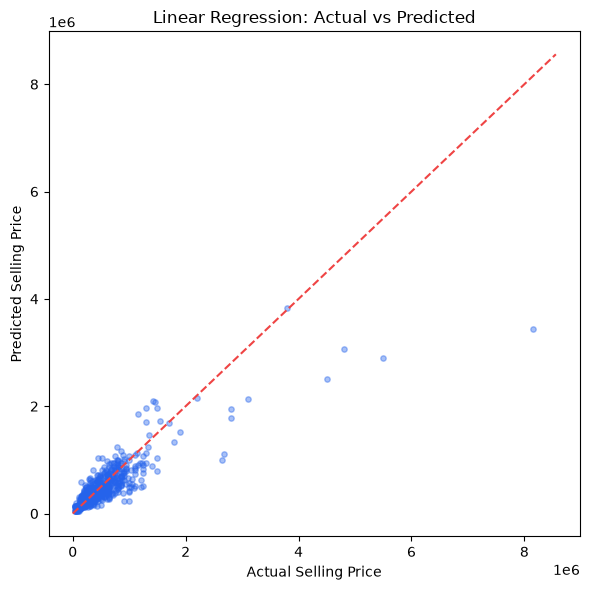

In [6]:
import matplotlib.pyplot as plt

best_preds = np.clip(fitted[best_name].predict(X_test), 0, None)
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, best_preds, alpha=0.4, s=15, color='#2563eb')
lims = [0, max(y_test.max(), best_preds.max()) * 1.05]
ax.plot(lims, lims, '--', color='#ef4444')
ax.set_xlabel('Actual Selling Price'); ax.set_ylabel('Predicted Selling Price')
ax.set_title(f'{best_name}: Actual vs Predicted')
plt.tight_layout()
plt.show()

**Note:** `python src/train_model.py` performs this exact process and additionally saves:
- `models/car_price_pipeline.pkl` (the winning pipeline, via `joblib.dump`)
- `reports/metrics.json` (everything in the comparison table above, for the Streamlit   Model Performance page)
- `reports/test_predictions.csv` (actual vs. predicted for every model, for charting)

Run the script directly rather than this notebook to regenerate those artifacts - see `README.md`.